In [35]:
import os, sys
cur_directory = os.getcwd()
project_folder = os.path.abspath(os.path.join(cur_directory, os.pardir, os.pardir))
save_directory = os.path.join(cur_directory, 'saved')
sys.path.append(os.path.join(project_folder, 'analysis-suite'))

In [36]:
import numpy as np
from numpy import linalg as la
import matplotlib as mpl
from matplotlib import pyplot as plt
import analyses as als
import datasets as ds
import models as mds
import tools
from random import sample
from tqdm import tqdm
from argparse import Namespace
from time import gmtime, strftime
import pickle

In [3]:
V_width = 1
V_E_buffer = 0
E_width = 1
stim_array = np.array(range(5))
train_fraction = 0.8
samp_keep = 1


In [4]:
Sig = []
mu = []
SigX = []
SigXY = []
SigY = []
train_points = []
test_points = []

for n in tqdm(stim_array):
    data_path = os.path.join(project_folder, 'data', 'nat_scenes_data')
    D = ds.DataNatScenes(data_path, mov_ind=n)
    print(f'current stimulus is {D.movname}')
    D.trim(20)
    V, E = D.create_V_and_E_datasets(V_width, V_E_buffer, E_width, samp_keep=samp_keep)
    (
        current_train_points,
        current_test_points,
    ) = tools.generate_train_test_indices(V.P, train_fraction)
    train_points.append(current_train_points)
    test_points.append(current_test_points)
    x_sel = np.arange(V.N)
    y_sel = np.arange(V.N, V.N + E.N)
    
    V.subset_points(current_train_points)
    E.subset_points(current_train_points)
    cur_mu = np.mean(np.r_[V.X, E.X], axis=1)
    mu.append(cur_mu)
    cur_Sig = np.cov(V.X, E.X)
    Sig.append(cur_Sig)
    SigX.append(cur_Sig[x_sel][:,x_sel])
    SigXY.append(cur_Sig[x_sel][:,y_sel])
    SigY.append(cur_Sig[y_sel][:,y_sel])

  0%|          | 0/5 [00:00<?, ?it/s]

current stimulus is bushes


 20%|██        | 1/5 [00:00<00:01,  2.65it/s]

current stimulus is water


 40%|████      | 2/5 [00:00<00:01,  2.38it/s]

current stimulus is leaves


 60%|██████    | 3/5 [00:01<00:00,  2.30it/s]

current stimulus is fish


 80%|████████  | 4/5 [00:01<00:00,  2.23it/s]

current stimulus is opticflow


100%|██████████| 5/5 [00:02<00:00,  2.25it/s]


In [25]:
def Gaussian_entropy(Sig):
    N = Sig.shape[0]
    return N / 2 + 1 / 2 * np.log(np.linalg.det(2 * np.pi * Sig))

def reg(Sig, alp):
    N = Sig.shape[0]
    return Sig + alp * np.eye(N)

def get_SigY_X(n, alp):
    A = SigY[n]
    B = SigXY[n]
    C = SigX[n]

    A_reg = reg(A, alp)
    C_reg = reg(C, alp)
    # Ny = A.shape[0]
    # Nx = C.shape[0]
    # A_reg = A + alp * np.eye(Ny)
    # C_reg = C + alp * np.eye(Nx)
    SigY_X = A_reg - B.T @ np.linalg.inv(C_reg) @ B
    return SigY_X

def eig_plot(Sig, alp):
    lam, V = np.linalg.eigh(Sig)
    plt.plot(np.log10(lam))
    plt.plot(np.log10(lam + alp))

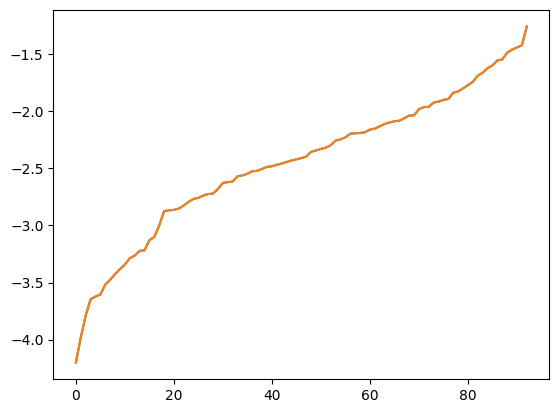

In [26]:
alp = 1E-7
eig_plot(SigY[0], alp)

In [27]:
# SigY_X_0 = [get_SigY_X(n, 0) for n in range(5)]
SigY_X_reg = [get_SigY_X(n, alp) for n in range(5)]
SigY_reg = [reg(SigY[n], alp) for n in range(5)]

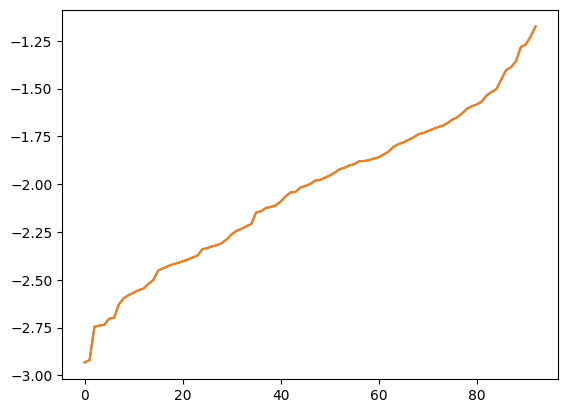

In [28]:
n = 4
eig_plot(SigY_X_reg[n], 0)

In [29]:
HY = []
HY_X = []
IXY = []
for n in range(5):
    HY.append(Gaussian_entropy(SigY_reg[n]))
    HY_X.append(Gaussian_entropy(SigY_X_reg[n]))
    IXY.append(HY[n] - HY_X[n])

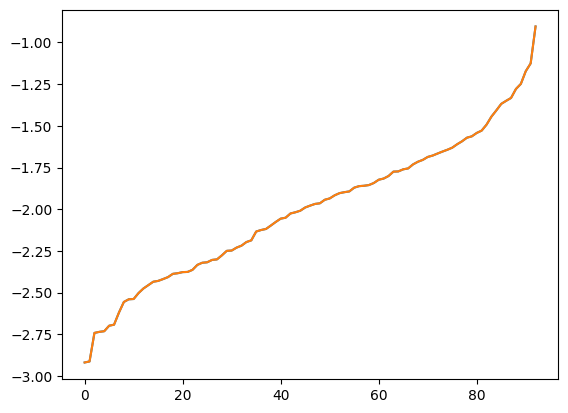

In [30]:
eig_plot(SigY[4], 1E-7)
# plt.ylim(-4)

In [31]:
HY_X / np.log(2)

array([-191.89365917, -299.73690046, -185.70636935, -179.54130232,
       -124.26084447])

In [32]:
HY / np.log(2)

array([-188.45053866, -294.94575205, -181.24043188, -174.38445366,
       -119.29561837])

In [33]:
alp

1e-07

In [34]:
IXY / np.log(2)

array([3.44312051, 4.79114841, 4.46593747, 5.15684866, 4.96522609])

In [159]:
save_vars = {
    "V_width",
    "V_E_buffer",
    "E_width",
    "train_fraction",
    "samp_keep",
    "Sig",
    "SigX",
    "SigXY",
    "SigY",
    "SigY_X_reg",
    "SigY_reg",
    "alp",
    "HY",
    "HY_X",
    "IXY",
}
local_dict = locals()
output_data = {k: local_dict[k] for k in save_vars}

In [160]:
save_directory

'/Users/adamkline/Projects/archive/metaneurons/analyses/architecture tests/saved'

In [ ]:
# save things
timestamp = strftime("%Y.%m.%d %Hh %Mm %Ss.dat",gmtime())
# full_file_path = os.path.join(save_directory, strftime("%Y.%m.%d %Hh %Mm %Ss",gmtime())+'.dat')

full_file_path = os.path.join(save_directory, f'Gaussian information {V_width, V_E_buffer, E_width} alp {alp}.dat')
# full_file_path = os.path.join(save_directory, stim, prepend + 'all neurons, trim 60.dat')
print(f"data will be saved to:\n{full_file_path}")

data will be saved to:
/Users/adamkline/Projects/archive/metaneurons/analyses/architecture tests/saved/Gaussian information (1, 0, 1).dat


In [162]:
os.makedirs(os.path.dirname(full_file_path), exist_ok=True)
with open(full_file_path, 'wb+') as f:
            pickle.dump(output_data, f)
tools.record_parameters(full_file_path, output_data)

# Cross-entropy validation

In [ ]:
def compute_surprise(V, E, mu, Sig):
    X_Y = np.r_[V.X, E.X]
    Sig_inv = np.linalg.inv(Sig)
    # energy = 1 / 2 * (X_Y - mu[:,None]).T @ Sig_inv @ (X_Y - mu[:,None])
    energy = 1 / 2 * np.einsum('ij,ik,jk->k',Sig_inv,X_Y - mu[:,None], X_Y - mu[:,None])
    logZ = 1 / 2 * np.log(np.linalg.det(2 * np.pi * Sig))
    return - np.mean(energy) + logZ

def surprise_alp(alp):
    surprises = []
    for n in range(5):
        data_path = os.path.join(project_folder, 'data', 'nat_scenes_data')
        D = ds.DataNatScenes(data_path, mov_ind=n)
        print(f'current stimulus is {D.movname}')
        D.trim(20)
        V, E = D.create_V_and_E_datasets(V_width, V_E_buffer, E_width, samp_keep=samp_keep)

        p = test_points[n]
        V.subset_points(p)
        E.subset_points(p)

        # Sig_inv = fast_Sig_inv(n, alp)
        Sig_reg = reg(Sig[n], alp)
        # Sig_inv = np.linalg.inv(Sig_reg)

        surprises.append(compute_surprise(V, E, mu[n], Sig_reg))

    return surprises

In [ ]:
# # surprises = []
# alp = 0.001
# # for n in range(1):
# n=1
# data_path = os.path.join(project_folder, 'data', 'nat_scenes_data')
# D = ds.DataNatScenes(data_path, mov_ind=n)
# print(f'current stimulus is {D.movname}')
# D.trim(20)
# V, E = D.create_V_and_E_datasets(V_width, V_E_buffer, E_width, samp_keep=samp_keep)

# p = test_points[n]
# V.subset_points(p)
# E.subset_points(p)

# # Sig_inv = fast_Sig_inv(n, alp)
# Sig_reg = reg(Sig[n], alp)
# # Sig_inv = np.linalg.inv(Sig_reg)

# surprises.append(compute_surprise(V, E, mu[n], Sig_reg))

In [ ]:
alp_array = np.logspace(-9,-3,40)
surprises = []
for n, alp in enumerate(alp_array):
    surprises.append(surprise_alp(alp))

surprises = np.array(surprises)

current stimulus is bushes
current stimulus is water


/var/folders/b8/k5811h914nsdmp3chwqpyd3w0000gn/T/ipykernel_52776/3410841913.py:6: RuntimeWarning: divide by zero encountered in log
  logZ = 1 / 2 * np.log(np.linalg.det(2 * np.pi * Sig))


current stimulus is leaves
current stimulus is fish
current stimulus is opticflow
current stimulus is bushes
current stimulus is water
current stimulus is leaves
current stimulus is fish
current stimulus is opticflow
current stimulus is bushes
current stimulus is water
current stimulus is leaves
current stimulus is fish
current stimulus is opticflow
current stimulus is bushes
current stimulus is water
current stimulus is leaves
current stimulus is fish
current stimulus is opticflow
current stimulus is bushes
current stimulus is water
current stimulus is leaves
current stimulus is fish
current stimulus is opticflow
current stimulus is bushes
current stimulus is water
current stimulus is leaves
current stimulus is fish
current stimulus is opticflow
current stimulus is bushes
current stimulus is water
current stimulus is leaves
current stimulus is fish
current stimulus is opticflow
current stimulus is bushes
current stimulus is water
current stimulus is leaves
current stimulus is fish
cur

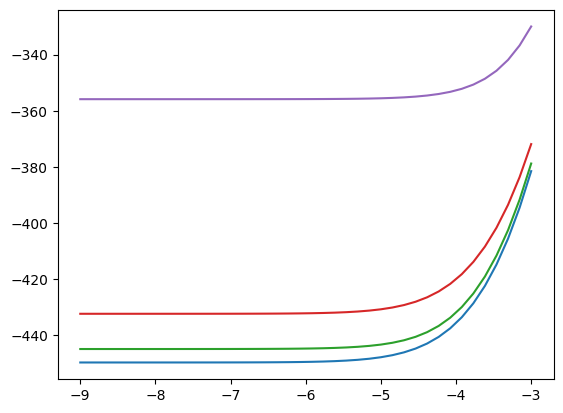

In [ ]:
plt.plot(np.log10(alp_array), surprises)

# Test different regularizations

In [68]:
def get_IXY(alp):
    SigY_X = [get_SigY_X(n, alp) for n in range(5)]
    SigY_reg = [reg(SigY[n], alp) for n in range(5)]   
    
    HY = []
    HY_X = []
    IXY = []
    for n in range(5):
        HY.append(Gaussian_entropy(SigY_reg[n]))
        HY_X.append(Gaussian_entropy(SigY_X[n]))
        IXY.append(HY[n] - HY_X[n])

    return np.array(HY), np.array(HY_X), np.array(IXY)

In [71]:
HY = []
HY_X = []
IXY = []
alp_array = np.logspace(-3,-1,50)
for alp in alp_array:
    cur_HY, cur_HY_X, cur_IXY = get_IXY(alp)
    HY.append(cur_HY)
    HY_X.append(cur_HY_X)
    IXY.append(cur_IXY)

HY = np.array(HY)
HY_X = np.array(HY_X)
IXY = np.array(IXY)

In [72]:
ctl = [0.509742438502167,
 0.17628864586768406,
 0.6537149748736802,
 0.793143338018919,
 1.1779072680354044]

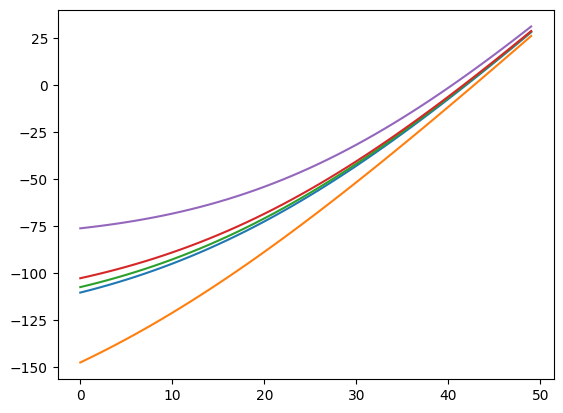

In [76]:
plt.plot(HY)

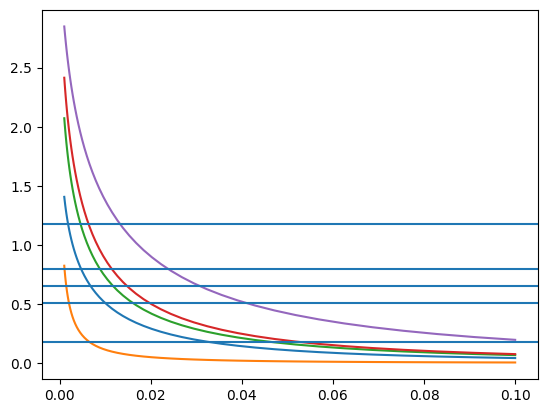

In [131]:
plt.plot(alp_array, IXY)
for n in range(5):
    plt.axhline(ctl[n])

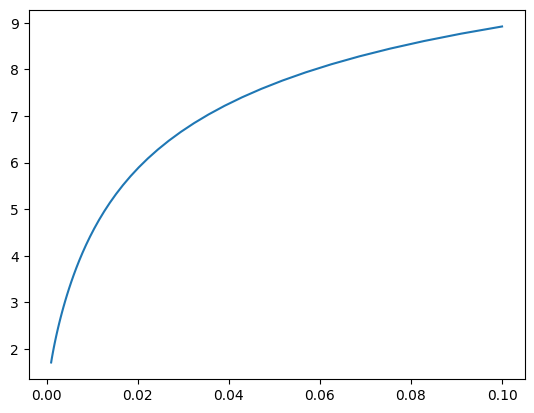

In [134]:
plt.plot(alp_array, IXY[:,0]/IXY[:,1])
# for n in range(5):
    # plt.axhline(ctl[n])